# NB1 · Main project

**Machine Learning I · Group Project 2026-27 · The Guild of Gentle Landings**

Group XX · Data Avionaries

---

This notebook covers the CRISP-DM steps from **Data Preparation** to **Evaluation**: cleaning, feature engineering, feature selection, model comparison, hyperparameter tuning, threshold tuning and the final evaluation. It ends with the specification of the final model used in NB9.

**How we avoid leakage.** The golden rule from the Model Assessment lecture: *every number learned from data is computed on the training part only*. So:
1. We first split `learn.csv` into **train (80%)** and **test (20%)**, stratified. The test set is opened **once**, at the very end, to judge the chosen model.
2. Cleaning and feature engineering are **row-by-row rules** (fix a typo, an impossible value becomes NaN, a difference between two columns). They learn nothing from the data, so they can be applied to any set.
3. Everything that *is* learned (medians for imputation, scaling, which categories are rare, feature selection, hyperparameters, the decision threshold) is fitted on the training data only. Inside cross-validation, imputation, scaling and encoding live in a scikit-learn `Pipeline`, so they are refitted **in each fold** on that fold's training part.

**Contents**
1. Setup
2. Data partition
3. Data preparation (cleaning)
4. Feature engineering
5. Preprocessing pipeline
6. Feature selection
7. Model comparison
8. Hyperparameter tuning
9. Decision threshold
10. Final evaluation on the test set
11. What makes an accident fatal?
12. Final model for NB9

## 1. Setup

In [1]:
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.stats import chi2_contingency, spearmanr
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import RFE
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, precision_recall_curve)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty.*")   # scikit-learn >= 1.8 warns that `penalty` will be renamed; behaviour is unchanged
pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")

SEED = 5   # every source of randomness uses this seed

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
scipy        1.18.1
matplotlib   3.11.2
seaborn      0.13.2


## 2. Data partition

In [2]:
learn = pd.read_csv("learn.csv")
predict = pd.read_csv("predict.csv")

X = learn.drop(columns=["row_id", "fatal"])
y = learn["fatal"]

# hold-out test set (20%), stratified so both parts keep the 17% fatal rate
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"train: {X_train.shape[0]:,} rows | fatal rate {y_train.mean():.3f}")
print(f"test:  {X_test.shape[0]:,} rows | fatal rate {y_test.mean():.3f}")

train: 13,583 rows | fatal rate 0.170
test:  3,396 rows | fatal rate 0.170


With ~17,000 rows we can afford a 20% test set (3,396 accidents, about 578 fatal) and still use **stratified 5-fold cross-validation** on the remaining 80% for every choice (features, models, hyperparameters, threshold). The same 5 folds are used for every model, so that differences between models come from the models and not from the split.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 3. Data preparation (cleaning)

The function below applies the decisions taken in NB0 (summary table, findings 2-10 and 13-15). Every rule works on a single row, so applying it to train, test and predict separately gives exactly the same result as applying it to all of them together: **no information flows between sets**.

In [4]:
def clean(df):
    """Rule-based cleaning: every rule looks at one row at a time, nothing is learned from the data."""
    df = df.copy()

    # 1. inconsistent spellings (air / AIR, n / N, ...)
    for col in ["acft_category", "homebuilt", "second_pilot", "acft_make"]:
        df[col] = df[col].str.upper().str.strip()

    # 2. columns with no useful information (see NB0, findings 2-5)
    df = df.drop(columns=["ev_country", "wx_temp_c", "gust_ind", "wind_dir_deg"])

    # 3. temperature and dew point: 0/0 means missing, impossible values -> NaN
    both_zero = (df["wx_temp"] == 0) & (df["wx_dew_pt"] == 0)
    df.loc[both_zero, ["wx_temp", "wx_dew_pt"]] = np.nan
    df.loc[(df["wx_temp"] > 130) | (df["wx_temp"] < -60), "wx_temp"] = np.nan
    df.loc[(df["wx_dew_pt"] > 100) | (df["wx_dew_pt"] < -60), "wx_dew_pt"] = np.nan

    # 4. altimeter: ~3000 is written without the decimal point; keep only 27-32 inHg (0 = missing)
    alt = df["altimeter"].where(df["altimeter"] < 2800, df["altimeter"] / 100)
    df["altimeter"] = alt.where(alt.between(27, 32))

    # 5. visibility is reported up to 10 statute miles
    df["vis_sm"] = df["vis_sm"].clip(upper=10)

    # 6. impossible weather and location values -> NaN
    df.loc[df["wind_vel_kts"] > 100, "wind_vel_kts"] = np.nan
    df.loc[df["gust_kts"] > 100, "gust_kts"] = np.nan
    df.loc[df["sky_ceil_ht"] > 40000, "sky_ceil_ht"] = np.nan
    df.loc[df["apt_dist"] > 500, "apt_dist"] = np.nan
    df.loc[df["apt_elev"] > 15000, "apt_elev"] = np.nan

    # 7. aircraft: impossible years and seat counts -> NaN
    bad_year = (df["acft_year"] < 1900) | (df["acft_year"] > df["ev_year"])
    df.loc[bad_year, "acft_year"] = np.nan
    df.loc[(df["total_seats"] == 0) | (df["total_seats"] > 600), "total_seats"] = np.nan

    # 8. engine power: horsepower only for non-jet engines (jets are in pounds of thrust)
    jet = df["eng_type"].isin(["TF", "TJ", "GTFN"])
    df["eng_power_hp"] = df["eng_power"].where(~jet)
    df.loc[(df["eng_power_hp"] == 0) | (df["eng_power_hp"] > 5000), "eng_power_hp"] = np.nan
    df = df.drop(columns="eng_power")

    # 9. pilot age outside 14-100 is a typing error
    df.loc[(df["pilot_age"] < 14) | (df["pilot_age"] > 100), "pilot_age"] = np.nan

    # 10. far_part codes that are not in the data dictionary -> UNK
    known = ["091", "137", "135", "121", "PUBU", "133", "129", "091K", "NUSN", "NUSC", "125"]
    df.loc[df["far_part"].notna() & ~df["far_part"].isin(known), "far_part"] = "UNK"
    return df

In [5]:
X_train_c = clean(X_train)
X_test_c = clean(X_test)

# effect of the cleaning on the training data: missing values before and after
before = X_train.isna().sum()
after = X_train_c.isna().sum()
compare = pd.DataFrame({"missing before": before, "missing after": after}).dropna()
compare = compare[compare["missing before"] != compare["missing after"]]
compare["new NaN (impossible / placeholder values)"] = compare["missing after"] - compare["missing before"]
compare.astype(int).sort_values("new NaN (impossible / placeholder values)", ascending=False)

,missing before,missing after,new NaN (impossible / placeholder values)
altimeter,0,1231,1231
wx_temp,0,696,696
wx_dew_pt,0,687,687
acft_year,5467,5536,69
apt_dist,0,43,43
total_seats,959,992,33
pilot_age,97,105,8
wind_vel_kts,2916,2918,2
sky_ceil_ht,0,1,1


In [6]:
# check: the cleaned values are now in plausible ranges
X_train_c[["wx_temp", "wx_dew_pt", "altimeter", "vis_sm", "wind_vel_kts", "gust_kts", "apt_dist",
           "apt_elev", "acft_year", "total_seats", "eng_power_hp", "pilot_age"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
wx_temp,12887.0,66.85,18.28,-30.00,56.00,70.00,81.00,124.00
wx_dew_pt,12896.0,44.98,20.43,-39.00,32.00,47.00,62.00,100.00
altimeter,12352.0,30.02,0.21,27.02,29.92,30.02,30.13,31.14
vis_sm,13000.0,9.55,1.59,0.00,10.00,10.00,10.00,10.00
wind_vel_kts,10665.0,7.85,4.50,0.00,5.00,7.00,10.00,100.00
gust_kts,13583.0,3.05,7.59,0.00,0.00,0.00,0.00,56.00
apt_dist,13540.0,1.09,8.61,0.00,0.00,0.00,0.00,417.00
apt_elev,8999.0,1346.56,1752.94,-224.00,162.00,700.00,1461.00,9955.00
acft_year,8047.0,1983.23,21.45,1916.00,1967.00,1979.00,2003.00,2023.00
total_seats,12591.0,5.66,20.30,1.00,2.00,4.00,4.00,400.00


The cleaning turned the placeholder and impossible values into honest missing values: 1,231 altimeter readings of 0, ~690 temperature/dew point pairs of 0/0, 69 impossible aircraft years, 43 impossible airport distances, 33 seat counts, 8 pilot ages. In addition, 54 altimeter values written without the decimal point were *repaired* (not removed), visibility was clipped at 10 miles, and `eng_power` was replaced by `eng_power_hp`.

All the ranges are now plausible (temperatures between −30 °F and 124 °F, altimeter 27-31 inHg, pilots aged 14-97, ...). The NaNs will be imputed inside the pipeline (section 5).

## 4. Feature engineering

New features, each motivated by a finding in NB0:

| New feature | Definition | Why |
|---|---|---|
| `acft_age` | `ev_year − acft_year` | The age of the aircraft at the accident is more meaningful than its build year (replaces `acft_year`) |
| `temp_dew_spread` | `wx_temp − wx_dew_pt` | A small spread means humid air, risk of fog and low clouds |
| `night` | `light_cond` in NITE, NDRK, NBRT | Night accidents were about twice as often fatal |
| `imc` | `wx_cond_basic == IMC` | Instrument conditions: 60% fatal rate |
| `off_airport` | `apt_dist > 0` | Accidents away from the airport were 2-3 times more often fatal |
| `log_apt_dist` | `log(1 + apt_dist)` | The distance is extremely skewed |
| `has_ceiling` | `sky_ceil_ht > 0` | A ceiling of 0 means "no ceiling", not a height |
| `has_gust` | `gust_kts > 0` | Replaces the unreliable `gust_ind` |
| `make` | first word of `acft_make` | Reduces 2,914 spellings of the manufacturer |

Some of these overlap with existing columns (e.g. `night` with `light_cond`). That is intended: feature selection (section 6) decides which version to keep.

In [7]:
def engineer(df):
    """New features built from the cleaned columns (one row at a time, nothing learned from the data)."""
    df = df.copy()
    df["acft_age"] = df["ev_year"] - df["acft_year"]                     # age of the aircraft at the accident
    df["temp_dew_spread"] = df["wx_temp"] - df["wx_dew_pt"]              # small spread = humid air, fog risk
    df["night"] = df["light_cond"].isin(["NITE", "NDRK", "NBRT"]).astype(int)
    df["imc"] = (df["wx_cond_basic"] == "IMC").astype(int)               # instrument meteorological conditions
    df["off_airport"] = (df["apt_dist"] > 0).astype(float).where(df["apt_dist"].notna())
    df["log_apt_dist"] = np.log1p(df["apt_dist"])                        # distance is very skewed
    df["has_ceiling"] = (df["sky_ceil_ht"] > 0).astype(int)
    df["has_gust"] = (df["gust_kts"] > 0).astype(int)
    df["make"] = df["acft_make"].str.split().str[0]                      # ROBINSON HELICOPTER CO -> ROBINSON
    df = df.drop(columns=["acft_make", "acft_year"])
    return df

In [8]:
X_train_fe = engineer(X_train_c)
X_test_fe = engineer(X_test_c)

print("acft_make values:", X_train_c["acft_make"].nunique(), "-> make values:", X_train_fe["make"].nunique())
print("features after engineering:", X_train_fe.shape[1])

# fatal rate of the new binary features (training data)
for col in ["night", "imc", "off_airport", "has_ceiling", "has_gust"]:
    rates = y_train.groupby(X_train_fe[col]).mean().round(3).to_dict()
    print(f"{col:12s} fatal rate by value: {rates}")

acft_make values: 2412 -> make values: 1731
features after engineering: 43
night        fatal rate by value: {0: 0.155, 1: 0.373}
imc          fatal rate by value: {0: 0.15, 1: 0.608}
off_airport  fatal rate by value: {0.0: 0.142, 1.0: 0.267}
has_ceiling  fatal rate by value: {0: 0.144, 1: 0.25}
has_gust     fatal rate by value: {0: 0.172, 1: 0.159}


The new binary features confirm the NB0 findings on the training data: **instrument conditions** (61% vs 15%), **night** (37% vs 16%), **off-airport** (27% vs 14%) and **a cloud ceiling** (25% vs 14%) are all associated with a much higher fatal rate. `has_gust` shows no difference (16% vs 17%): gusty wind does not seem to make accidents more lethal. The first word of the manufacturer reduces its categories from 2,412 to 1,731 in the training set; the rare ones are grouped by the encoder.

## 5. Preprocessing pipeline

The steps that **learn from the data** go into a `ColumnTransformer` + `Pipeline`, so that `fit` only ever sees training rows (in CV: the training folds):

- **numerical features** → `SimpleImputer(strategy="median", add_indicator=True)` (median is robust to skewness; the indicators keep the information that a value was missing, which NB0 showed is related to the target) → `StandardScaler` (needed by logistic regression with regularisation and by KNN, which are distance/scale sensitive; harmless for trees).
- **categorical features** → `SimpleImputer(strategy="constant", fill_value="MISSING")` → `OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist")`: categories with fewer than 30 training rows are merged into one *infrequent* column, and categories never seen in training (possible in `predict.csv`) are mapped to it instead of breaking the model.

In [9]:
def make_preprocessor(num_features, cat_features):
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
                         ("onehot", OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_features), ("cat", cat_pipe, cat_features)])

num_all = X_train_fe.select_dtypes(include="number").columns.tolist()
cat_all = X_train_fe.select_dtypes(exclude="number").columns.tolist()
print(len(num_all), "numerical:", num_all)
print(len(cat_all), "categorical:", cat_all)

pre = make_preprocessor(num_all, cat_all).fit(X_train_fe)
print("\ncolumns after preprocessing:", len(pre.get_feature_names_out()))

25 numerical: ['ev_year', 'ev_month', 'ev_hour', 'sky_ceil_ht', 'vis_sm', 'wx_temp', 'wx_dew_pt', 'wind_vel_kts', 'gust_kts', 'altimeter', 'apt_dist', 'apt_elev', 'ifr_equipped_cert', 'num_eng', 'total_seats', 'pilot_age', 'eng_power_hp', 'acft_age', 'temp_dew_spread', 'night', 'imc', 'off_airport', 'log_apt_dist', 'has_ceiling', 'has_gust']
18 categorical: ['ev_dow', 'light_cond', 'wx_cond_basic', 'sky_cond_ceil', 'sky_cond_nonceil', 'far_part', 'acft_category', 'homebuilt', 'fixed_retractable', 'type_fly', 'flt_plan_filed', 'second_pilot', 'eng_type', 'carb_fuel_injection', 'pilot_sex', 'pilot_med_certf', 'phase', 'make']



columns after preprocessing: 193


## 6. Feature selection

Following the Feature Selection lecture, we combine **filter**, **wrapper** and **embedded** methods, all computed on the **training data only**. Each method gives a vote "keep" or "discard" for every original feature; features discarded by most methods are removed. Finally we check with cross-validation that removing them does not hurt.

Because a categorical feature becomes several one-hot columns, the results of the model-based methods are added back to the original feature (a feature is "kept" if any of its columns is kept).

### 6.1. Filter: constant and quasi-constant features

In [10]:
# share of the most frequent value of each feature (training data)
top_share = X_train_fe.apply(lambda col: col.value_counts(normalize=True, dropna=False).iloc[0])
top_share.sort_values(ascending=False).head(8).round(3)

imc              0.955
wx_cond_basic    0.950
night            0.929
light_cond       0.895
far_part         0.881
homebuilt        0.862
num_eng          0.859
vis_sm           0.859
dtype: float64

No feature is constant after cleaning (`ev_country` was already removed). The most unbalanced ones are `imc` / `wx_cond_basic` (95% VMC) and `night` (93% day). They are **quasi-constant**, but the rare value is exactly the dangerous one (60% fatal under IMC), so removing them would be a mistake: a low variance is not the same as low relevance. We keep them and let the next methods decide.

### 6.2. Filter: redundancy between numerical features (Spearman)

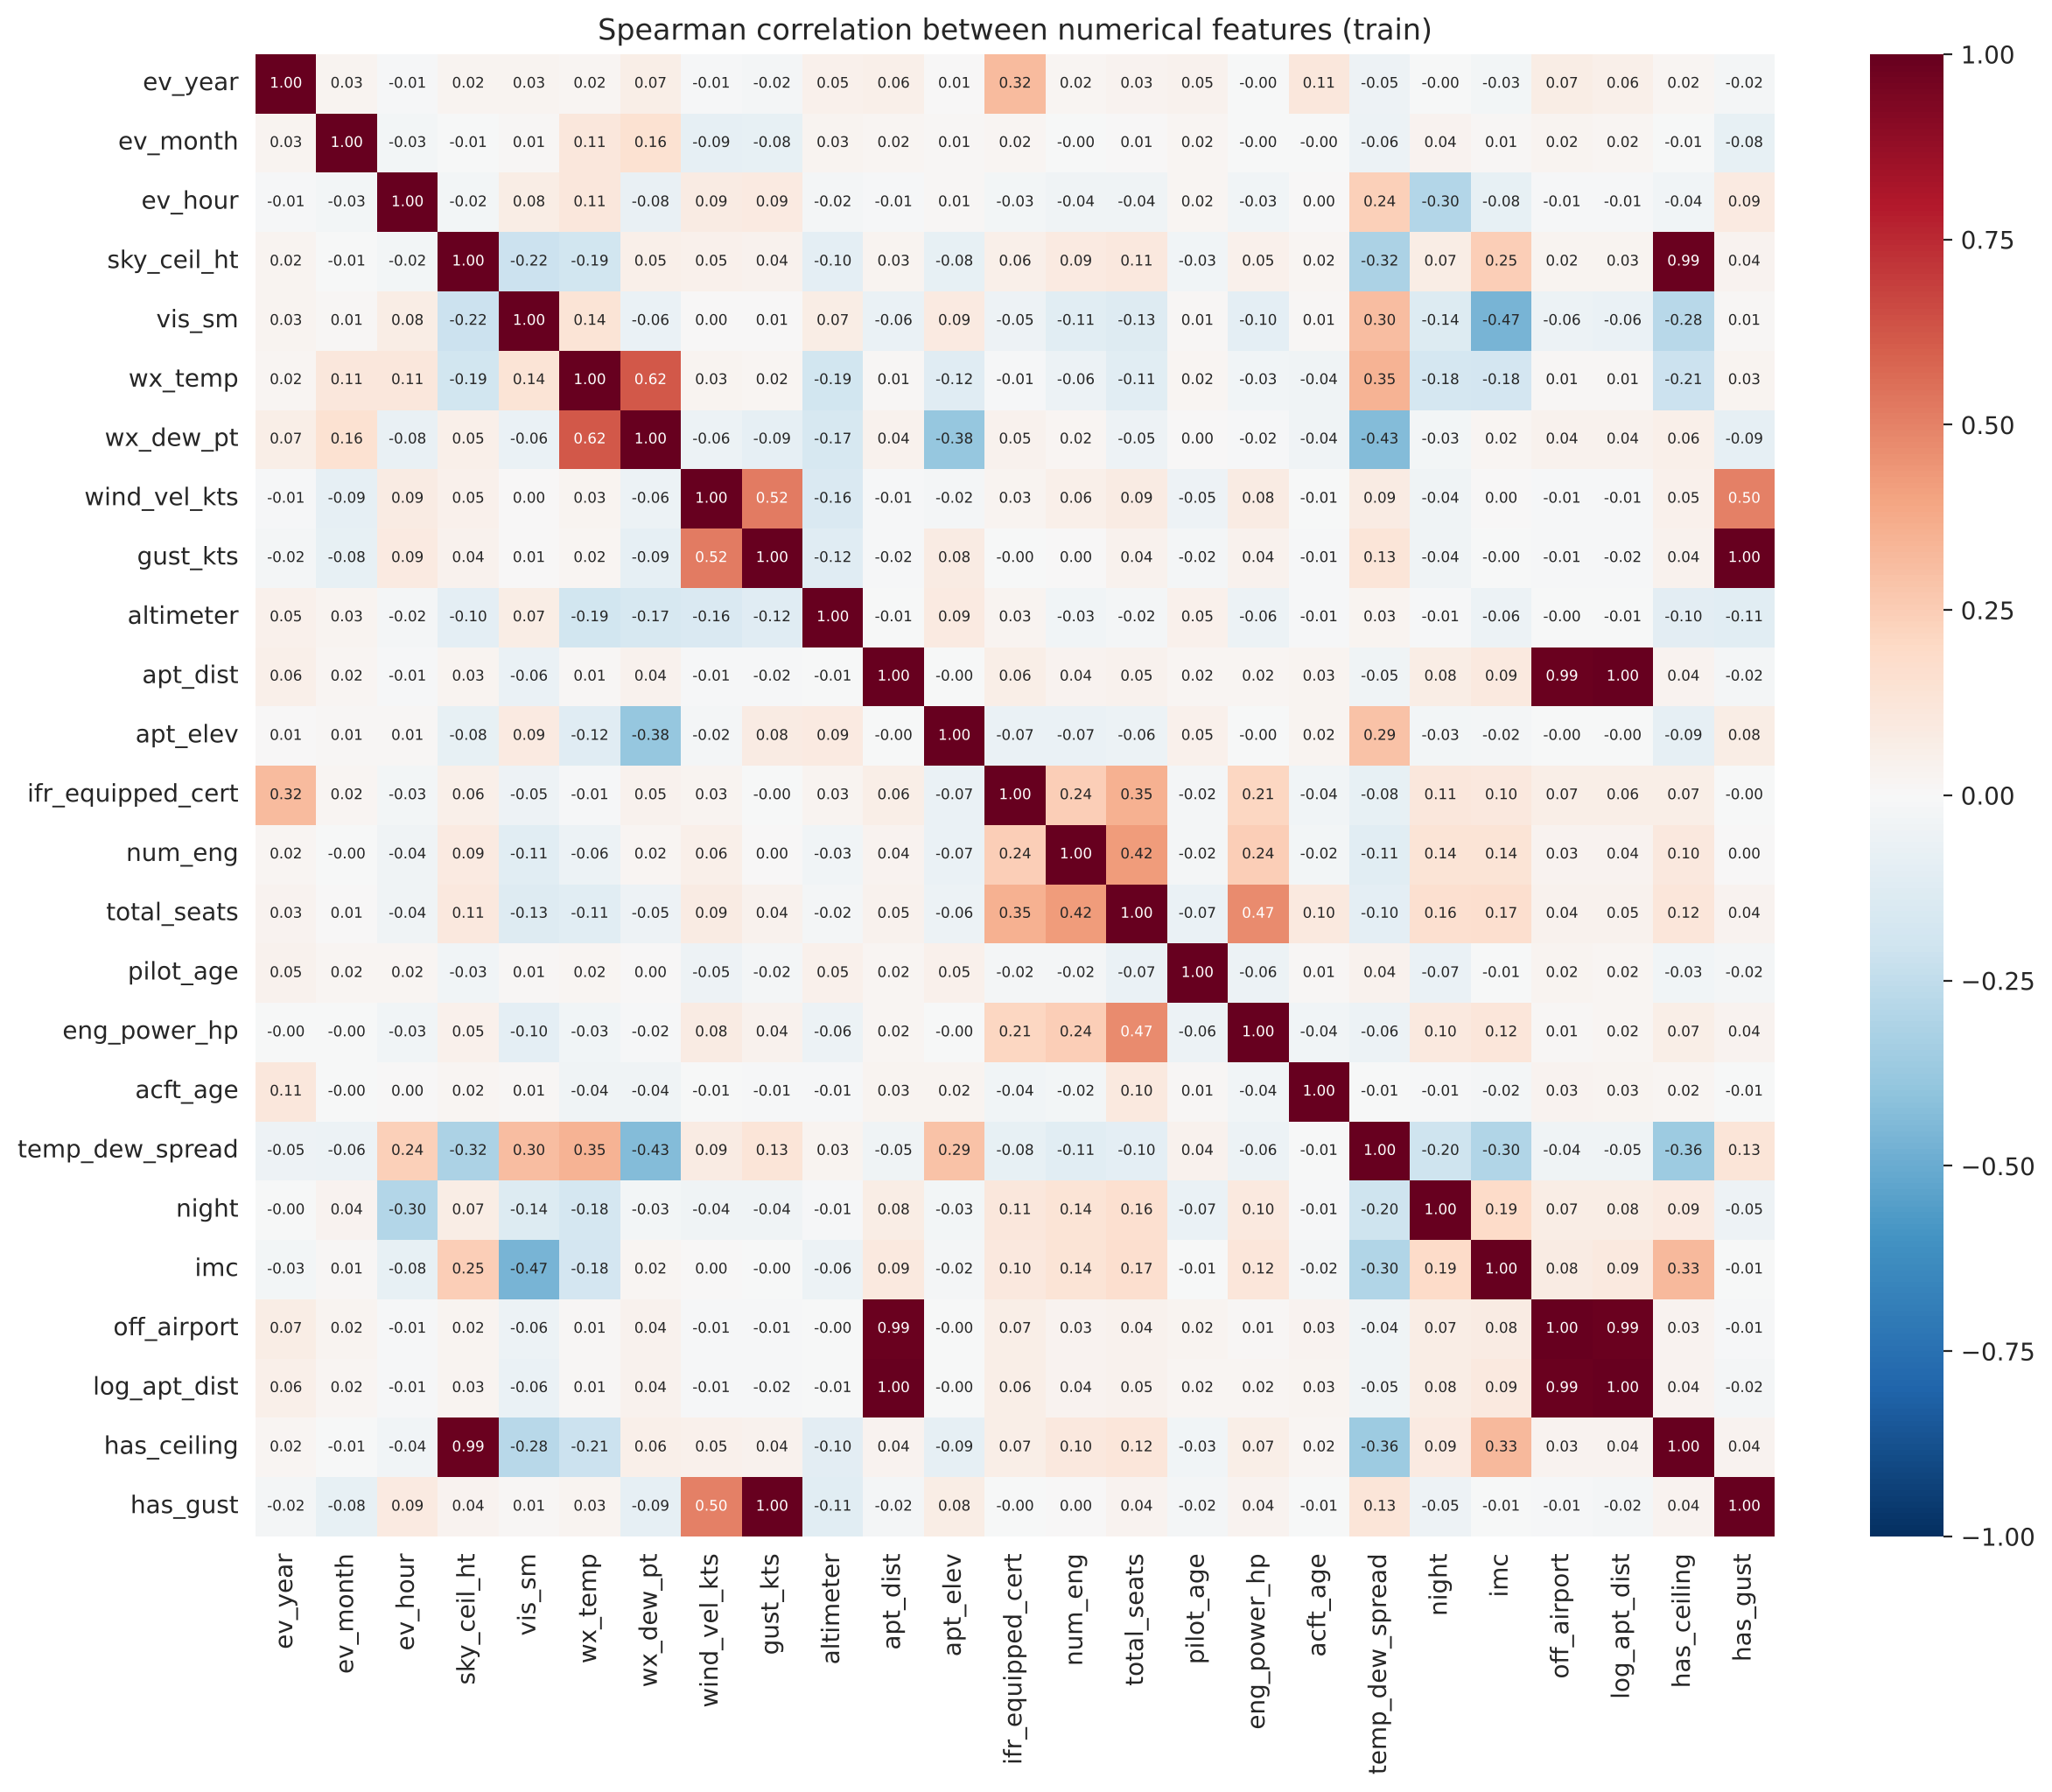

sky_ceil_ht  has_ceiling     0.987
gust_kts     has_gust        0.995
apt_dist     off_airport     0.992
             log_apt_dist    1.000
off_airport  log_apt_dist    0.992
dtype: float64

In [11]:
corr = X_train_fe[num_all].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 6}, ax=ax)
ax.set_title("Spearman correlation between numerical features (train)")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs[pairs.abs() > 0.8].round(3)

Spearman |ρ| > 0.8 only appears between a feature and the version we engineered from it:
- `apt_dist` / `log_apt_dist` (ρ = 1, since a log does not change the ranks) and `off_airport` (0.99);
- `sky_ceil_ht` / `has_ceiling` (0.99), because the height is 0 whenever there is no ceiling;
- `gust_kts` / `has_gust` (0.995).

For each pair we keep only one feature, the one more correlated with the target (next table): **`log_apt_dist`** (drop `apt_dist` and `off_airport`), **`has_ceiling`** (drop `sky_ceil_ht`). `gust_kts` and `has_gust` are both irrelevant for the target and are discarded in 6.6 anyway.

### 6.3. Filter: relevance for the target (Spearman for numerical, chi-square for categorical)

In [12]:
rows = []
for col in num_all:
    ok = X_train_fe[col].notna()
    rho, p = spearmanr(X_train_fe.loc[ok, col], y_train[ok])
    rows.append([col, "numerical", "Spearman", rho, p])
for col in cat_all:
    table = pd.crosstab(X_train_fe[col].fillna("MISSING"), y_train)
    chi2, p, dof, _ = chi2_contingency(table)
    rows.append([col, "categorical", "chi-square", chi2, p])

filters = pd.DataFrame(rows, columns=["feature", "type", "test", "statistic", "p-value"]).set_index("feature")
filters["filter keep"] = filters["p-value"] < 0.05
filters.sort_values("p-value").round(4)

,type,test,statistic,p-value,filter keep
feature,,,,,
phase,categorical,chi-square,1763.5644,0.0000,True
imc,numerical,Spearman,0.2522,0.0000,True
wx_cond_basic,categorical,chi-square,900.5797,0.0000,True
light_cond,categorical,chi-square,400.6011,0.0000,True
night,numerical,Spearman,0.1491,0.0000,True
apt_dist,numerical,Spearman,0.1464,0.0000,True
log_apt_dist,numerical,Spearman,0.1464,0.0000,True
off_airport,numerical,Spearman,0.1383,0.0000,True
sky_cond_ceil,categorical,chi-square,267.8055,0.0000,True


With ~13,600 training rows, even tiny effects become "significant", so the filters mainly flag what is clearly **irrelevant**: the day of the week (`ev_dow`), the year (`ev_year`), wind speed and gusts (`wind_vel_kts`, `gust_kts`, `has_gust`), the altimeter and the airport elevation have no significant relation with fatality (p > 0.05). At the top, `phase`, `imc` / `wx_cond_basic`, `light_cond` / `night` and the distance to the airport confirm the EDA.

### 6.4. Wrapper: Recursive Feature Elimination (RFE) with logistic regression

In [13]:
X_train_pre = pd.DataFrame(pre.transform(X_train_fe), columns=pre.get_feature_names_out(), index=X_train_fe.index)

def original_feature(column_name):
    # 'num__pilot_age', 'num__missingindicator_pilot_age', 'cat__phase_Landing' -> original feature name
    name = column_name.split("__", 1)[1].replace("missingindicator_", "")
    matches = [f for f in num_all + cat_all if name == f or name.startswith(f + "_")]
    return max(matches, key=len)

col_to_feature = pd.Series([original_feature(c) for c in X_train_pre.columns], index=X_train_pre.columns)

start = time.time()
rfe = RFE(LogisticRegression(class_weight="balanced", max_iter=2000), n_features_to_select=0.5, step=5)
rfe.fit(X_train_pre, y_train)
print(f"RFE took {time.time() - start:.0f}s; kept {rfe.support_.sum()} of {len(rfe.support_)} columns")

rfe_keep = pd.Series(rfe.support_, index=X_train_pre.columns).groupby(col_to_feature).any()
print("features with no column kept by RFE:", rfe_keep[~rfe_keep].index.tolist())

RFE took 5s; kept 96 of 193 columns
features with no column kept by RFE: ['acft_age', 'apt_dist', 'carb_fuel_injection', 'eng_power_hp', 'ev_hour', 'ev_month', 'ev_year', 'gust_kts', 'has_ceiling', 'has_gust', 'ifr_equipped_cert', 'imc', 'night', 'num_eng', 'off_airport', 'pilot_sex', 'sky_ceil_ht', 'temp_dew_spread', 'total_seats', 'vis_sm', 'wind_vel_kts']


### 6.5. Embedded: Lasso (L1-penalised logistic regression) and decision tree importance

Lasso kept 46 of 193 columns
features with all coefficients = 0: ['apt_dist', 'eng_type', 'ev_dow', 'ev_month', 'flt_plan_filed', 'gust_kts', 'ifr_equipped_cert', 'light_cond', 'pilot_sex', 'sky_cond_ceil', 'sky_cond_nonceil', 'wx_cond_basic', 'wx_temp']

features with tree importance < 0.005: ['apt_dist', 'apt_elev', 'carb_fuel_injection', 'eng_type', 'ev_dow', 'ev_hour', 'ev_month', 'ev_year', 'flt_plan_filed', 'gust_kts', 'has_ceiling', 'has_gust', 'homebuilt', 'ifr_equipped_cert', 'imc', 'light_cond', 'log_apt_dist', 'num_eng', 'off_airport', 'pilot_sex', 'second_pilot', 'sky_ceil_ht', 'sky_cond_ceil', 'sky_cond_nonceil', 'total_seats', 'vis_sm', 'wind_vel_kts']


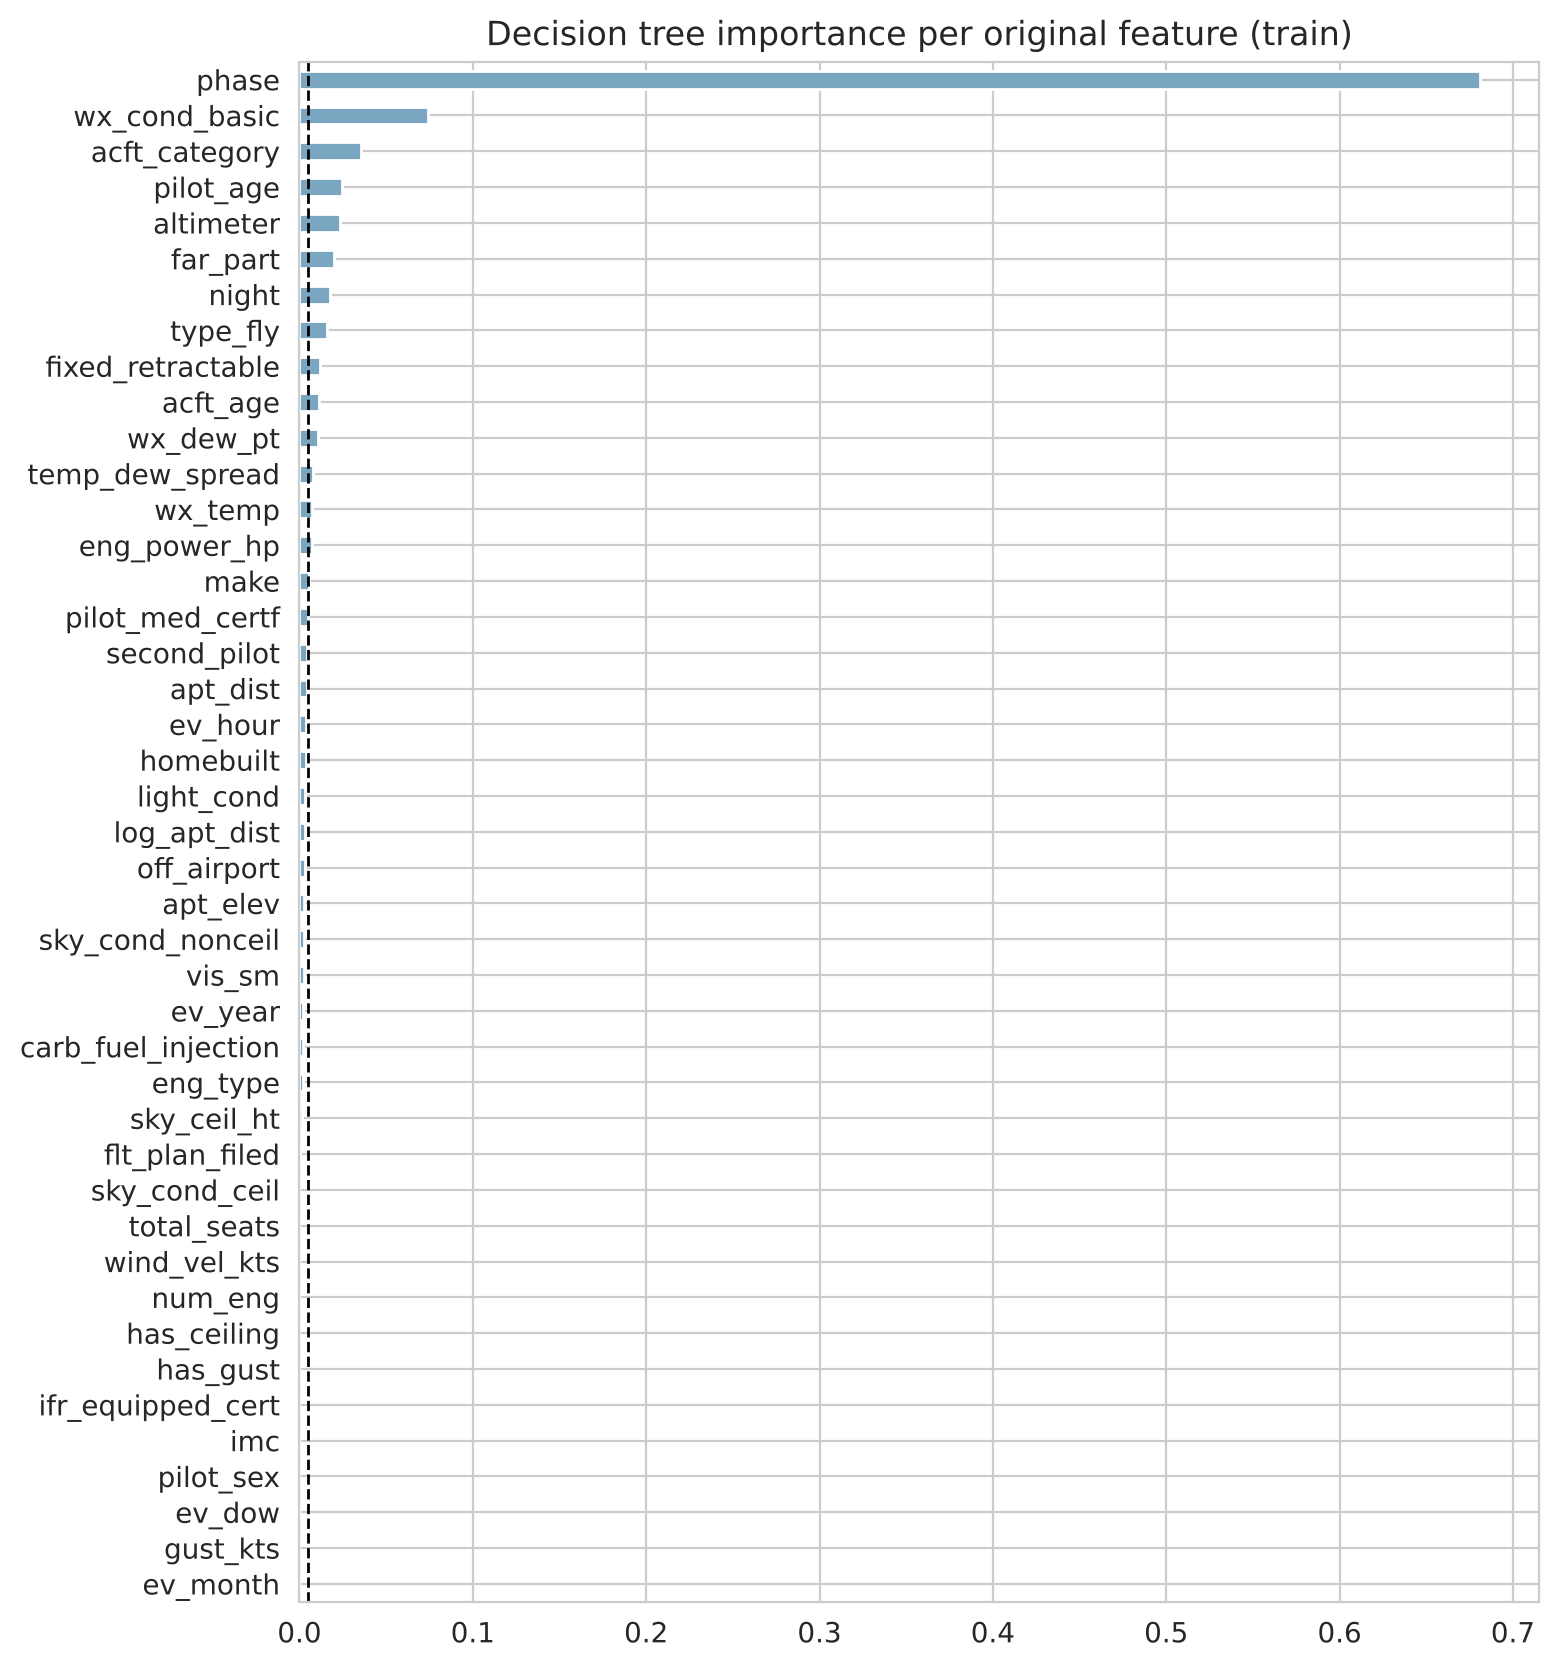

In [14]:
# Lasso: the L1 penalty pushes the coefficients of useless columns to exactly 0
lasso = LogisticRegression(penalty="l1", solver="liblinear", C=0.02, class_weight="balanced", random_state=SEED)
lasso.fit(X_train_pre, y_train)
coefs = pd.Series(lasso.coef_[0], index=X_train_pre.columns)
lasso_keep = (coefs != 0).groupby(col_to_feature).any()
print(f"Lasso kept {(coefs != 0).sum()} of {len(coefs)} columns")
print("features with all coefficients = 0:", lasso_keep[~lasso_keep].index.tolist())

# Decision tree: total impurity decrease of each feature
tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=30, class_weight="balanced", random_state=SEED)
tree.fit(X_train_pre, y_train)
tree_imp = pd.Series(tree.feature_importances_, index=X_train_pre.columns).groupby(col_to_feature).sum()
tree_keep = tree_imp >= 0.005
print("\nfeatures with tree importance < 0.005:", tree_keep[~tree_keep].index.tolist())

fig, ax = plt.subplots(figsize=(8, 10))
tree_imp.sort_values().plot.barh(ax=ax, color="#7aa6c2")
ax.axvline(0.005, color="black", linestyle="--", linewidth=1)
ax.set_title("Decision tree importance per original feature (train)")
plt.show()

The three model-based methods agree on the strong features (`phase`, `far_part`, `type_fly`, `acft_category`, `fixed_retractable`, `make`, `pilot_age`, ...). Their disagreements are informative:
- **RFE and the tree drop `imc` and `night`, and Lasso drops `wx_cond_basic` and `light_cond`**. This is not a contradiction: they carry the *same* information (IMC appears both as the flag and as a category), so each method keeps one version and discards the other. This is exactly the redundancy the lecture warns about.
- RFE discards most numerical features because logistic regression gets more from the one-hot categories; the tree, which can split numerical features at any point, keeps `pilot_age`, `acft_age`, `wx_dew_pt`, `eng_power_hp`.

That is why we combine the votes instead of trusting a single method.

### 6.6. Final decision

In [15]:
votes = pd.DataFrame({"filter (Spearman / chi2)": filters["filter keep"],
                      "RFE": rfe_keep,
                      "Lasso": lasso_keep,
                      "Decision tree": tree_keep}).loc[num_all + cat_all]
votes["keep votes"] = votes.sum(axis=1)
votes.sort_values("keep votes")

,filter (Spearman / chi2),RFE,Lasso,Decision tree,keep votes
gust_kts,False,False,False,False,0
ev_year,False,False,True,False,1
wind_vel_kts,False,False,True,False,1
ev_month,True,False,False,False,1
apt_dist,True,False,False,False,1
ifr_equipped_cert,True,False,False,False,1
has_gust,False,False,True,False,1
ev_dow,False,True,False,False,1
pilot_sex,True,False,False,False,1
total_seats,True,False,True,False,2


In [16]:
# discard: features kept by at most 1 of the 4 methods, plus the redundant features from 6.2
redundant = ["apt_dist", "off_airport", "sky_ceil_ht"]
weak = votes.index[votes["keep votes"] <= 1].tolist()
to_drop = sorted(set(weak + redundant))
print("dropped:", to_drop)

num_sel = [f for f in num_all if f not in to_drop]
cat_sel = [f for f in cat_all if f not in to_drop]
print(f"\nkept {len(num_sel)} numerical + {len(cat_sel)} categorical features")

dropped: ['apt_dist', 'ev_dow', 'ev_month', 'ev_year', 'gust_kts', 'has_gust', 'ifr_equipped_cert', 'off_airport', 'pilot_sex', 'sky_ceil_ht', 'wind_vel_kts']

kept 16 numerical + 16 categorical features


**Wrapper check.** Does removing these features hurt? We compare logistic regression and a random forest with all the features and with the selected ones, on the same 5 folds.

In [17]:
check_models = {"Logistic regression": LogisticRegression(class_weight="balanced", max_iter=2000),
                "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                                        n_jobs=-1, random_state=SEED)}
rows = []
for name, model in check_models.items():
    for label, (nums, cats) in {"all features": (num_all, cat_all), "selected": (num_sel, cat_sel)}.items():
        pipe = Pipeline([("pre", make_preprocessor(nums, cats)), ("model", model)])
        scores = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring="f1")["test_score"]
        rows.append([name, label, len(nums) + len(cats), scores.mean(), scores.std()])

pd.DataFrame(rows, columns=["model", "feature set", "n features", "F1 mean", "F1 std"]).round(4)

,model,feature set,n features,F1 mean,F1 std
0,Logistic regression,all features,43,0.5031,0.0084
1,Logistic regression,selected,32,0.5034,0.0070
2,Random forest,all features,43,0.5292,0.0145
3,Random forest,selected,32,0.5398,0.0157


We removed **11 features** (43 → 32): the 8 features kept by at most one method (`ev_year`, `ev_month`, `ev_dow`, `wind_vel_kts`, `gust_kts`, `has_gust`, `ifr_equipped_cert`, `pilot_sex`) plus the 3 redundant ones from 6.2 (`apt_dist`, `off_airport`, `sky_ceil_ht`).

The wrapper check confirms the choice: with 25% fewer features, logistic regression keeps the same F1 (0.503) and the random forest **improves** from 0.529 to 0.540, because it no longer wastes splits on noise. The selected set is used from now on.

*Note:* the selection was made once on the full training set, so the cross-validation scores from here on are slightly optimistic (the folds' validation rows took part in the selection). This is why the final estimate comes only from the test set, which played no part in any choice.

## 7. Model comparison

We compare the models seen in class: a **dummy** baseline (ZeroR-like, always predicts fatal), **logistic regression**, **k-nearest neighbours**, **Gaussian Naive Bayes**, a **decision tree**, and a **random forest** (an ensemble of decision trees, also discussed in the feature selection and model assessment lectures). All use the selected features, the same preprocessing pipeline and the **same 5 folds**.

To deal with the imbalance, the models that support it use `class_weight="balanced"` (errors on fatal accidents weigh ~5 times more). KNN and Naive Bayes do not support class weights, which puts them at a disadvantage at the default threshold of 0.5. To compare fairly, we also report the F1 at the **best threshold** found on the out-of-fold probabilities (each probability comes from a model that did not see that row).

In [18]:
models = {
    "Dummy (always 1)": DummyClassifier(strategy="constant", constant=1),
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Gaussian NB": GaussianNB(),
    "Decision tree": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
}

thresholds = np.arange(0.05, 0.96, 0.01)
results, fold_scores = {}, {}
for name, model in models.items():
    start = time.time()
    pipe = Pipeline([("pre", make_preprocessor(num_sel, cat_sel)), ("model", model)])
    cvres = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring=["f1", "precision", "recall"], return_train_score=True)
    proba = cross_val_predict(pipe, X_train_fe, y_train, cv=cv, method="predict_proba")[:, 1]
    best_f1 = max(f1_score(y_train, proba >= th) for th in thresholds)
    fold_scores[name] = cvres["test_f1"]
    results[name] = {"train F1": cvres["train_f1"].mean(), "val F1": cvres["test_f1"].mean(), "val F1 std": cvres["test_f1"].std(),
                     "val precision": cvres["test_precision"].mean(), "val recall": cvres["test_recall"].mean(),
                     "val F1 (best threshold)": best_f1, "time (s)": time.time() - start}

comparison = pd.DataFrame(results).T.round(3)
comparison

,train F1,val F1,val F1 std,val precision,val recall,val F1 (best threshold),time (s)
Dummy (always 1),0.291,0.291,0.000,0.170,1.000,0.291,2.263
Logistic regression,0.519,0.503,0.007,0.368,0.798,0.535,4.287
KNN (k=15),0.311,0.281,0.025,0.676,0.178,0.427,7.071
Gaussian NB,0.445,0.432,0.016,0.295,0.807,0.446,2.302
Decision tree,1.000,0.378,0.023,0.375,0.382,0.379,4.126
Random forest,1.000,0.353,0.016,0.729,0.234,0.533,21.131


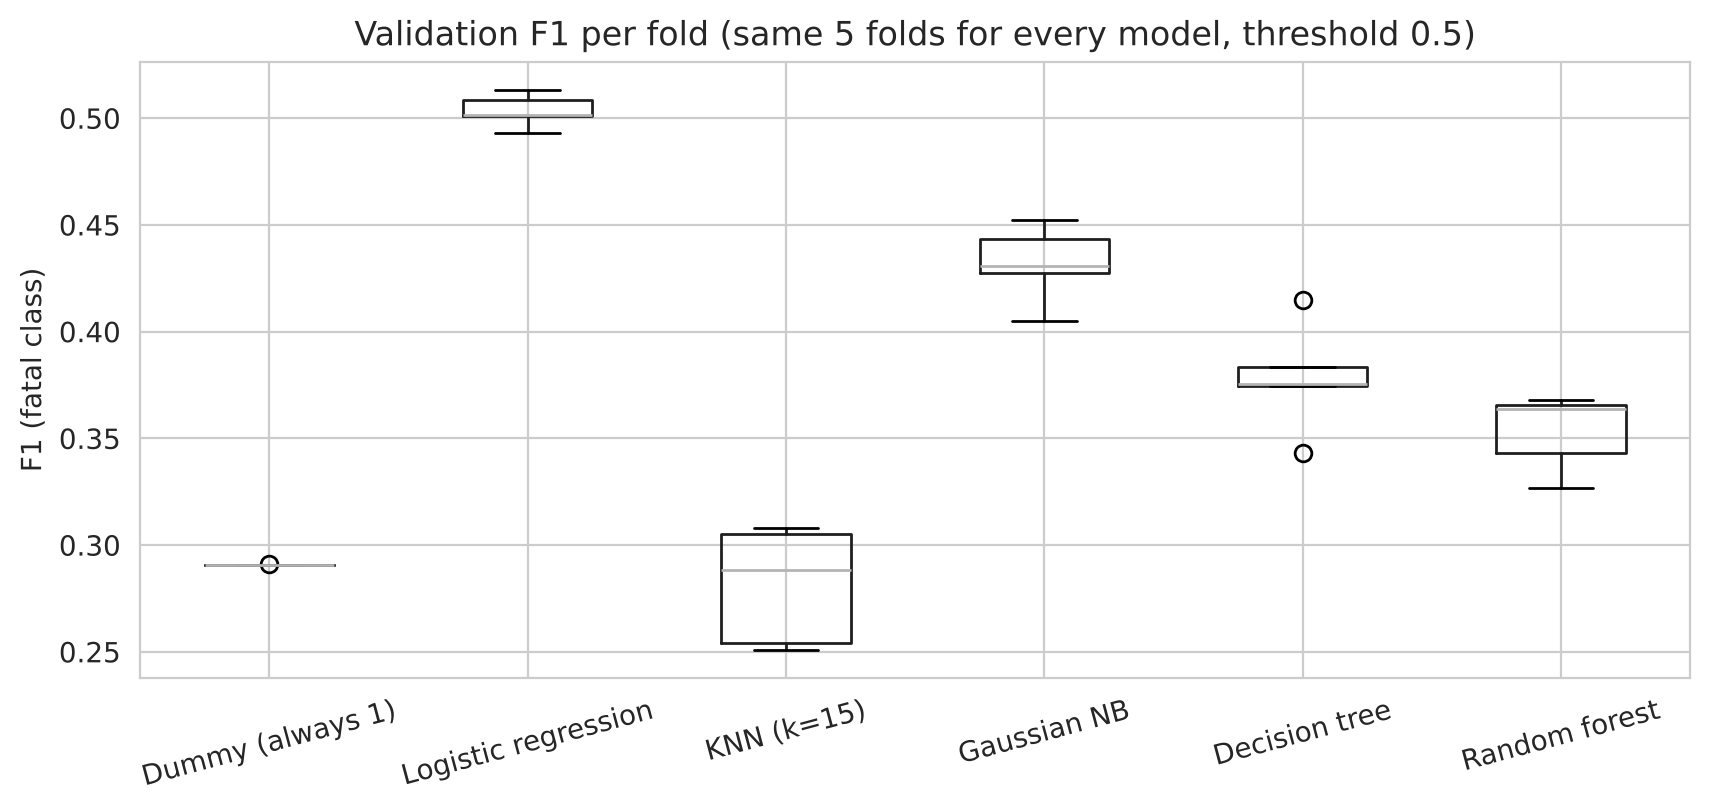

,Dummy (always 1),Logistic regression,KNN (k=15),Gaussian NB,Decision tree,Random forest
fold 1,0.291,0.509,0.308,0.452,0.415,0.366
fold 2,0.291,0.501,0.254,0.443,0.343,0.327
fold 3,0.291,0.501,0.288,0.405,0.374,0.368
fold 4,0.291,0.513,0.305,0.431,0.376,0.364
fold 5,0.291,0.493,0.251,0.427,0.384,0.343


In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
pd.DataFrame(fold_scores).boxplot(ax=ax)
ax.set_title("Validation F1 per fold (same 5 folds for every model, threshold 0.5)")
ax.set_ylabel("F1 (fatal class)")
plt.xticks(rotation=15)
plt.show()

# fold by fold
pd.DataFrame(fold_scores, index=[f"fold {i+1}" for i in range(5)]).round(3)

**Reading the table**
- The **dummy** that always predicts "fatal" gets F1 = 0.29 (the bar every model must clear).
- **Logistic regression** is the best model at the default threshold (0.503) and the most stable (std 0.007, the same score in every fold). Its training F1 (0.519) is close to the validation one: no overfitting.
- **Decision tree** and **random forest** reach **F1 = 1.000 on the training data** and much less on validation: unpruned trees memorise the training accidents (overfitting). The forest also has very low recall at 0.5 (23%): its votes rarely reach 50% for a minority class. But at the best threshold it is as good as logistic regression (0.533): its probabilities rank the accidents well, it just needs pruning (`min_samples_leaf`) and/or another threshold.
- **KNN** and **Naive Bayes** stay well below (0.43-0.45 even at the best threshold). KNN suffers from ~190 mostly one-hot dimensions (curse of dimensionality), and Naive Bayes from its independence assumption, which is clearly violated here (`imc` and `wx_cond_basic`, `night` and `light_cond`, ...).

→ We tune **logistic regression**, the **random forest** and, for reference, the **decision tree** (an interpretable single tree).

## 8. Hyperparameter tuning

We tune the three most promising models with `GridSearchCV` on the same 5 folds, scoring F1. The grids are based on what we saw in class (regularisation strength for logistic regression, depth and leaf size to pre-prune the trees, number of neighbours and weighting for KNN):

In [20]:
pipe_lr = Pipeline([("pre", make_preprocessor(num_sel, cat_sel)), ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
pipe_rf = Pipeline([("pre", make_preprocessor(num_sel, cat_sel)),
                    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])
pipe_dt = Pipeline([("pre", make_preprocessor(num_sel, cat_sel)), ("model", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))])

grids = {
    "Logistic regression": (pipe_lr, {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3],
                                      "model__penalty": ["l2", "l1"],
                                      "model__solver": ["liblinear"]}),
    "Random forest": (pipe_rf, {"model__max_depth": [10, 20, None],
                                "model__min_samples_leaf": [3, 5, 10],
                                "model__max_features": ["sqrt", 0.3]}),
    "Decision tree": (pipe_dt, {"model__criterion": ["gini", "entropy"],
                                "model__max_depth": [6, 8, 10, 12],
                                "model__min_samples_leaf": [10, 30, 60]}),
}

searches = {}
for name, (pipe, grid) in grids.items():
    start = time.time()
    search = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1)
    search.fit(X_train_fe, y_train)
    searches[name] = search
    print(f"{name}: {time.time() - start:.0f}s | best F1 = {search.best_score_:.4f} | {search.best_params_}")

Logistic regression: 47s | best F1 = 0.5043 | {'model__C': 0.3, 'model__penalty': 'l1', 'model__solver': 'liblinear'}


Random forest: 303s | best F1 = 0.5410 | {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}


Decision tree: 17s | best F1 = 0.4721 | {'model__criterion': 'gini', 'model__max_depth': 12, 'model__min_samples_leaf': 60}


In [21]:
# top 5 combinations of each search
for name, search in searches.items():
    res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    print(name)
    print(res[["params", "mean_test_score", "std_test_score"]].head(5).to_string(index=False))
    print()

Logistic regression
                                                                 params  mean_test_score  std_test_score
{'model__C': 0.3, 'model__penalty': 'l1', 'model__solver': 'liblinear'}         0.504281        0.006699
  {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}         0.503759        0.007054
{'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}         0.503248        0.007618
{'model__C': 0.3, 'model__penalty': 'l2', 'model__solver': 'liblinear'}         0.502672        0.007451
  {'model__C': 1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}         0.501976        0.005790

Random forest
                                                                                 params  mean_test_score  std_test_score
{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}         0.540968        0.018474
    {'model__max_depth': 20, 'model__max_features': 0.3, 'model__min_samples_leaf': 10}      

**Results** (run time on our laptop: LR ~45 s, random forest ~5 min, decision tree ~20 s)
- **Logistic regression** is insensitive to the regularisation: every C between 0.1 and 1, with L1 or L2, gives F1 ≈ 0.503-0.504. The model is limited by its linear form, not by overfitting.
- **Random forest** gains the most: with `min_samples_leaf=5` (each leaf needs at least 5 accidents) the trees no longer memorise the data, and F1 at 0.5 rises from 0.353 to **0.541**. Fully grown depth (`max_depth=None`) with `max_features="sqrt"` is best, but the top 4 combinations are within 0.005 of each other, well inside one standard deviation (≈ 0.015-0.018).
- **Decision tree**: pruning (depth 12, 60 rows per leaf) lifts it from 0.378 to 0.472, still clearly below the other two. A single tree has high variance; the forest averages 300 of them.

## 9. Decision threshold

A classifier gives a probability; the default rule "fatal if p ≥ 0.5" is not necessarily the one that maximises F1 (Model Assessment lecture: *accuracy, and every other metric, depends on where scores become decisions*). We choose the threshold on the **out-of-fold probabilities of the training set**, never on the test set.

Logistic regression: F1 at 0.50 = 0.5042 | best F1 = 0.5376 at threshold 0.67


Random forest: F1 at 0.50 = 0.5410 | best F1 = 0.5410 at threshold 0.50


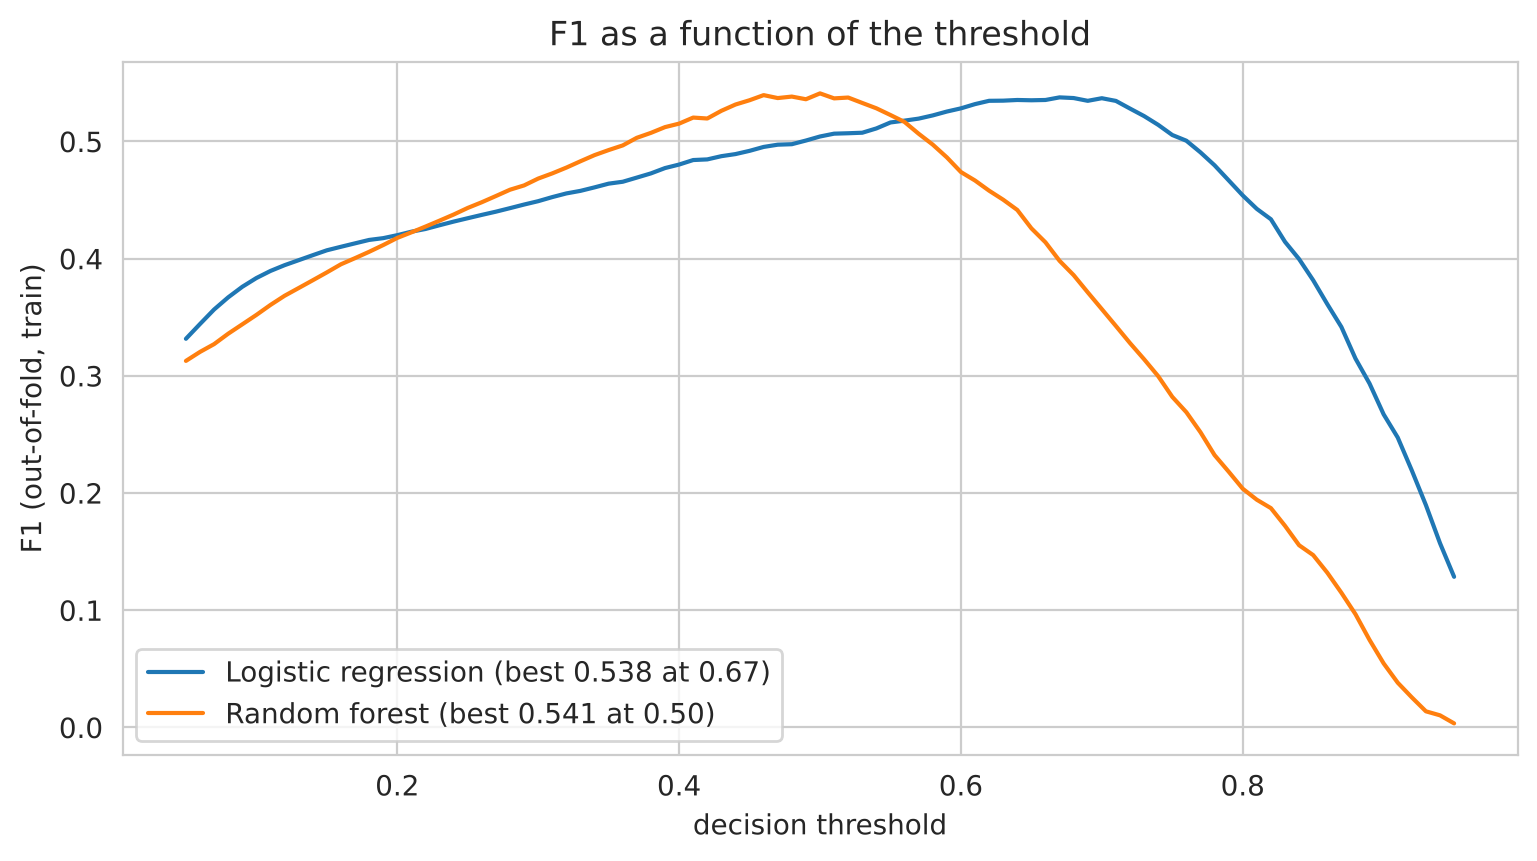

In [22]:
oof, best_threshold = {}, {}
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in ["Logistic regression", "Random forest"]:
    oof[name] = cross_val_predict(searches[name].best_estimator_, X_train_fe, y_train, cv=cv, method="predict_proba")[:, 1]
    f1s = [f1_score(y_train, oof[name] >= th) for th in thresholds]
    best = round(thresholds[int(np.argmax(f1s))], 2)
    best_threshold[name] = best
    ax.plot(thresholds, f1s, label=f"{name} (best {max(f1s):.3f} at {best:.2f})")
    print(f"{name}: F1 at 0.50 = {f1_score(y_train, oof[name] >= 0.5):.4f} | best F1 = {max(f1s):.4f} at threshold {best:.2f}")
ax.set_xlabel("decision threshold")
ax.set_ylabel("F1 (out-of-fold, train)")
ax.set_title("F1 as a function of the threshold")
ax.legend()
plt.show()

- **Logistic regression** gains a lot from moving the threshold to ~0.67 (0.504 → 0.538): with `class_weight="balanced"` it predicts "fatal" too often (recall 80%, precision 37%), and a higher threshold trades some recall for precision.
- The **tuned random forest** is already at its best around 0.5 (0.541), and its curve is **flat** between ~0.45 and 0.55, so the choice of threshold is not fragile.

**Final choice: random forest** (300 trees, `min_samples_leaf=5`, `max_features="sqrt"`, balanced class weights), threshold **0.50**. It has the highest cross-validated F1 at its best threshold (0.541 vs 0.538) and it does not depend on a threshold far from the default. The difference with logistic regression is small, so we keep logistic regression as an interpretable companion in section 11.

In [23]:
# final choice (justified above)
FINAL_NAME = "Random forest"
final_threshold = best_threshold[FINAL_NAME]
final_model = searches[FINAL_NAME].best_estimator_
print(FINAL_NAME, "| threshold:", final_threshold)
print(final_model.named_steps["model"])

Random forest | threshold: 0.5
RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=5,
                       n_estimators=300, n_jobs=-1, random_state=5)


## 10. Final evaluation on the test set

The test set has not been used for any decision so far. We now open it **once** to estimate how the chosen model (trained on the full training set, with the chosen threshold) performs on new accidents. No choice is changed after this point.

In [24]:
final_model.fit(X_train_fe, y_train)
proba_test = final_model.predict_proba(X_test_fe)[:, 1]
pred_test = (proba_test >= final_threshold).astype(int)

print(f"test F1:        {f1_score(y_test, pred_test):.4f}")
print(f"test precision: {precision_score(y_test, pred_test):.4f}")
print(f"test recall:    {recall_score(y_test, pred_test):.4f}")
print(f"test accuracy:  {accuracy_score(y_test, pred_test):.4f}")
print(f"(F1 with the default 0.5 threshold: {f1_score(y_test, proba_test >= 0.5):.4f})")
print()
print(classification_report(y_test, pred_test, target_names=["not fatal", "fatal"]))

test F1:        0.5313
test precision: 0.5199
test recall:    0.5433
test accuracy:  0.8369
(F1 with the default 0.5 threshold: 0.5313)

              precision    recall  f1-score   support

   not fatal       0.91      0.90      0.90      2818
       fatal       0.52      0.54      0.53       578

    accuracy                           0.84      3396
   macro avg       0.71      0.72      0.72      3396
weighted avg       0.84      0.84      0.84      3396



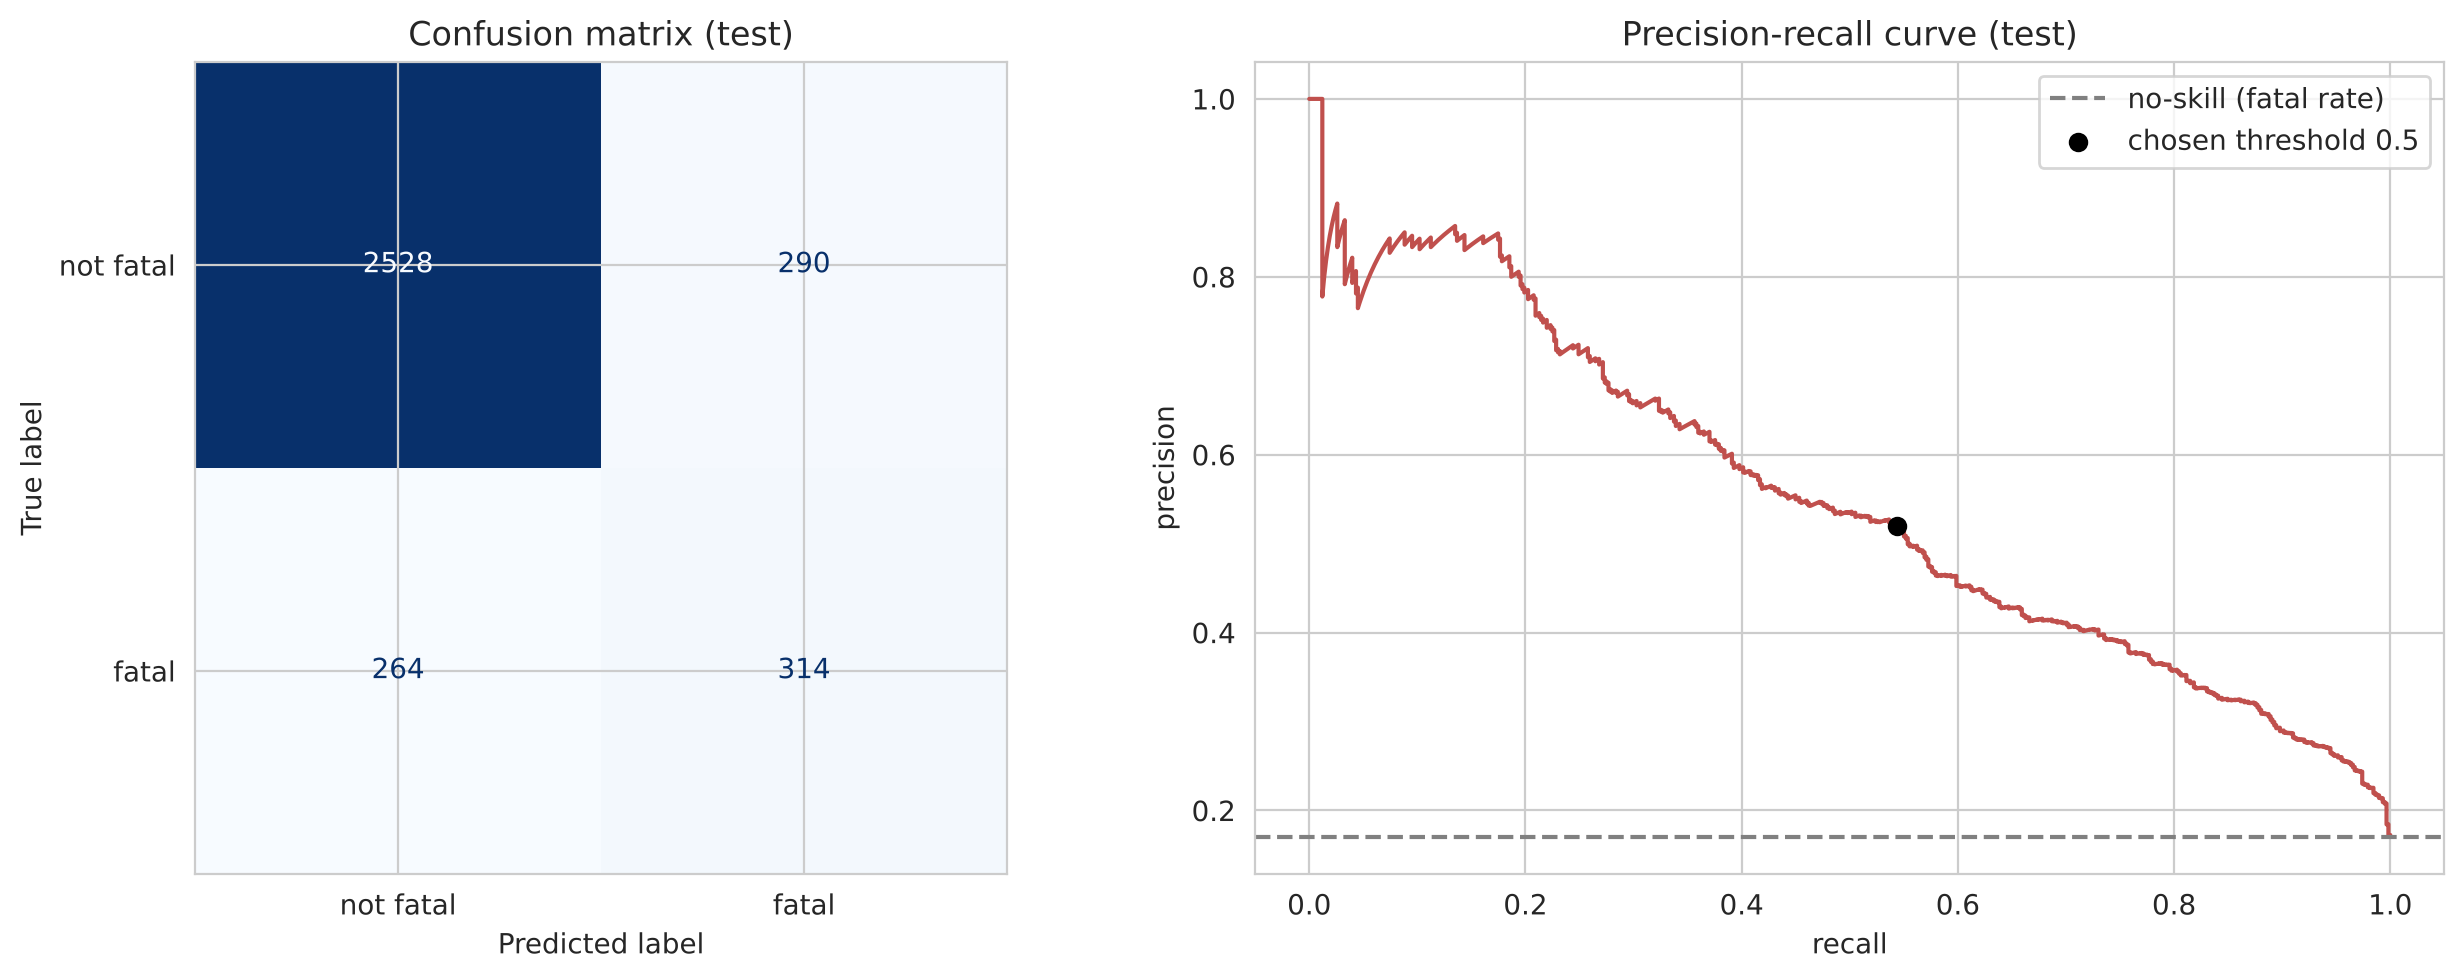

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["not fatal", "fatal"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test)")

prec, rec, ths = precision_recall_curve(y_test, proba_test)
axes[1].plot(rec, prec, color="#c0504d")
axes[1].axhline(y_test.mean(), color="grey", linestyle="--", label="no-skill (fatal rate)")
axes[1].scatter(recall_score(y_test, pred_test), precision_score(y_test, pred_test), color="black", zorder=3, label=f"chosen threshold {final_threshold}")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

On the **test set**, never used before, the random forest reaches **F1 = 0.531** (precision 0.52, recall 0.54), close to the cross-validated estimate (0.541): the model generalises, and the slight optimism of the CV scores (see 6.6) was small.

What this means for the Guild: of the 578 fatal accidents in the test set, the model flags **54%**; and when it flags an accident as fatal, it is right **52%** of the time, three times better than flagging at random (17%). The precision-recall curve shows the trade-off: if the Guild prefers to miss fewer fatal accidents, a lower threshold raises recall at the cost of more false alarms. Accuracy (0.84) is reported only for completeness: "always not fatal" would already get 0.83.

## 11. What makes an accident fatal?

Besides predicting, the Guild wants to understand which conditions make accidents more severe. We use **permutation importance on the test set** (how much F1 drops when one original feature is shuffled; it works for any model and on data the model was not trained on), and the coefficients of the logistic regression (their sign shows the direction of the effect).

took 27s


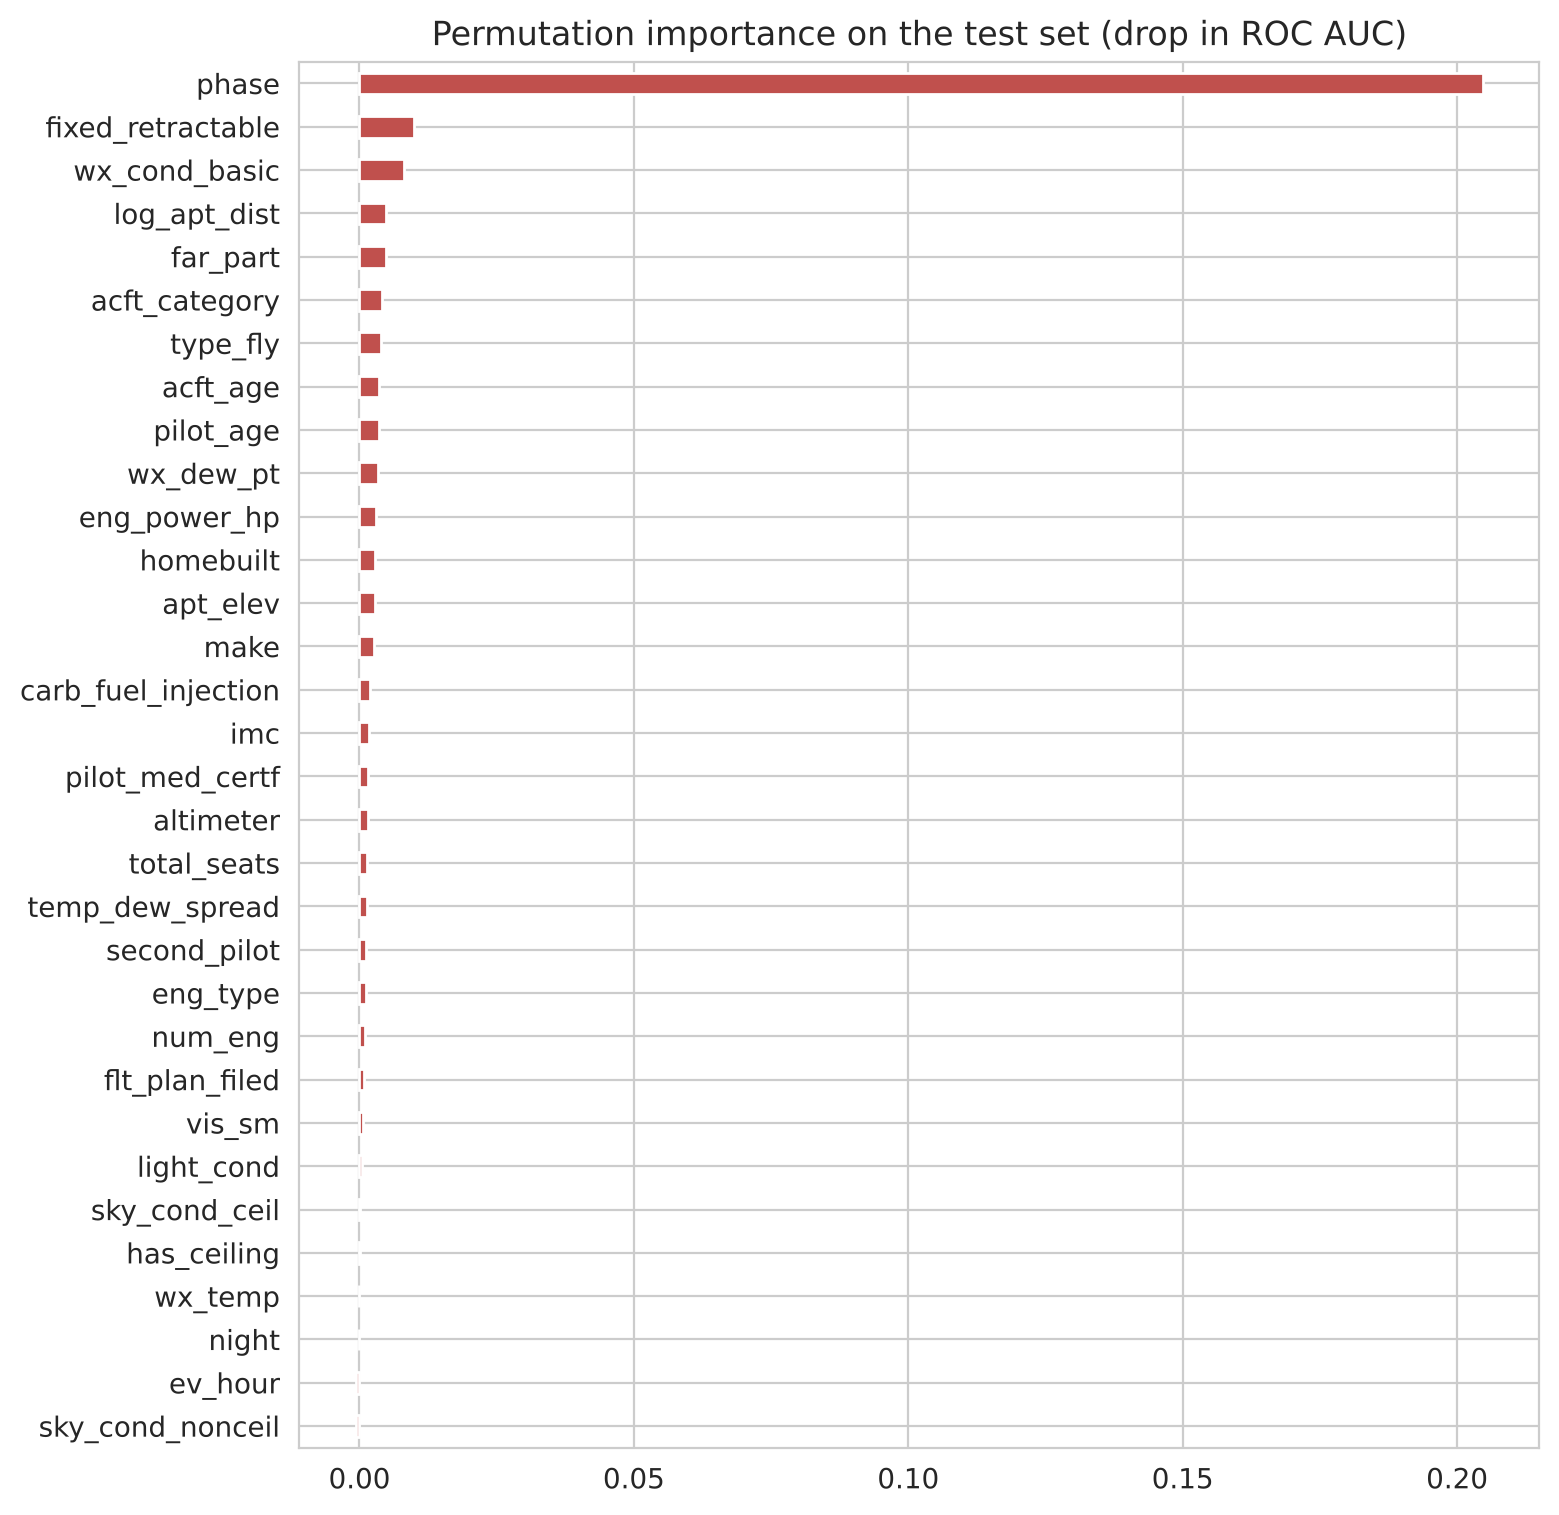

In [26]:
start = time.time()
perm = permutation_importance(final_model, X_test_fe, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
print(f"took {time.time() - start:.0f}s")
importance = pd.Series(perm.importances_mean, index=X_test_fe.columns).loc[num_sel + cat_sel].sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
importance.plot.barh(ax=ax, color="#c0504d")
ax.set_title("Permutation importance on the test set (drop in ROC AUC)")
plt.show()

*(We measure the drop in ROC AUC rather than F1 because it uses the probabilities and is much less noisy than a thresholded metric for single-feature shuffles.)*

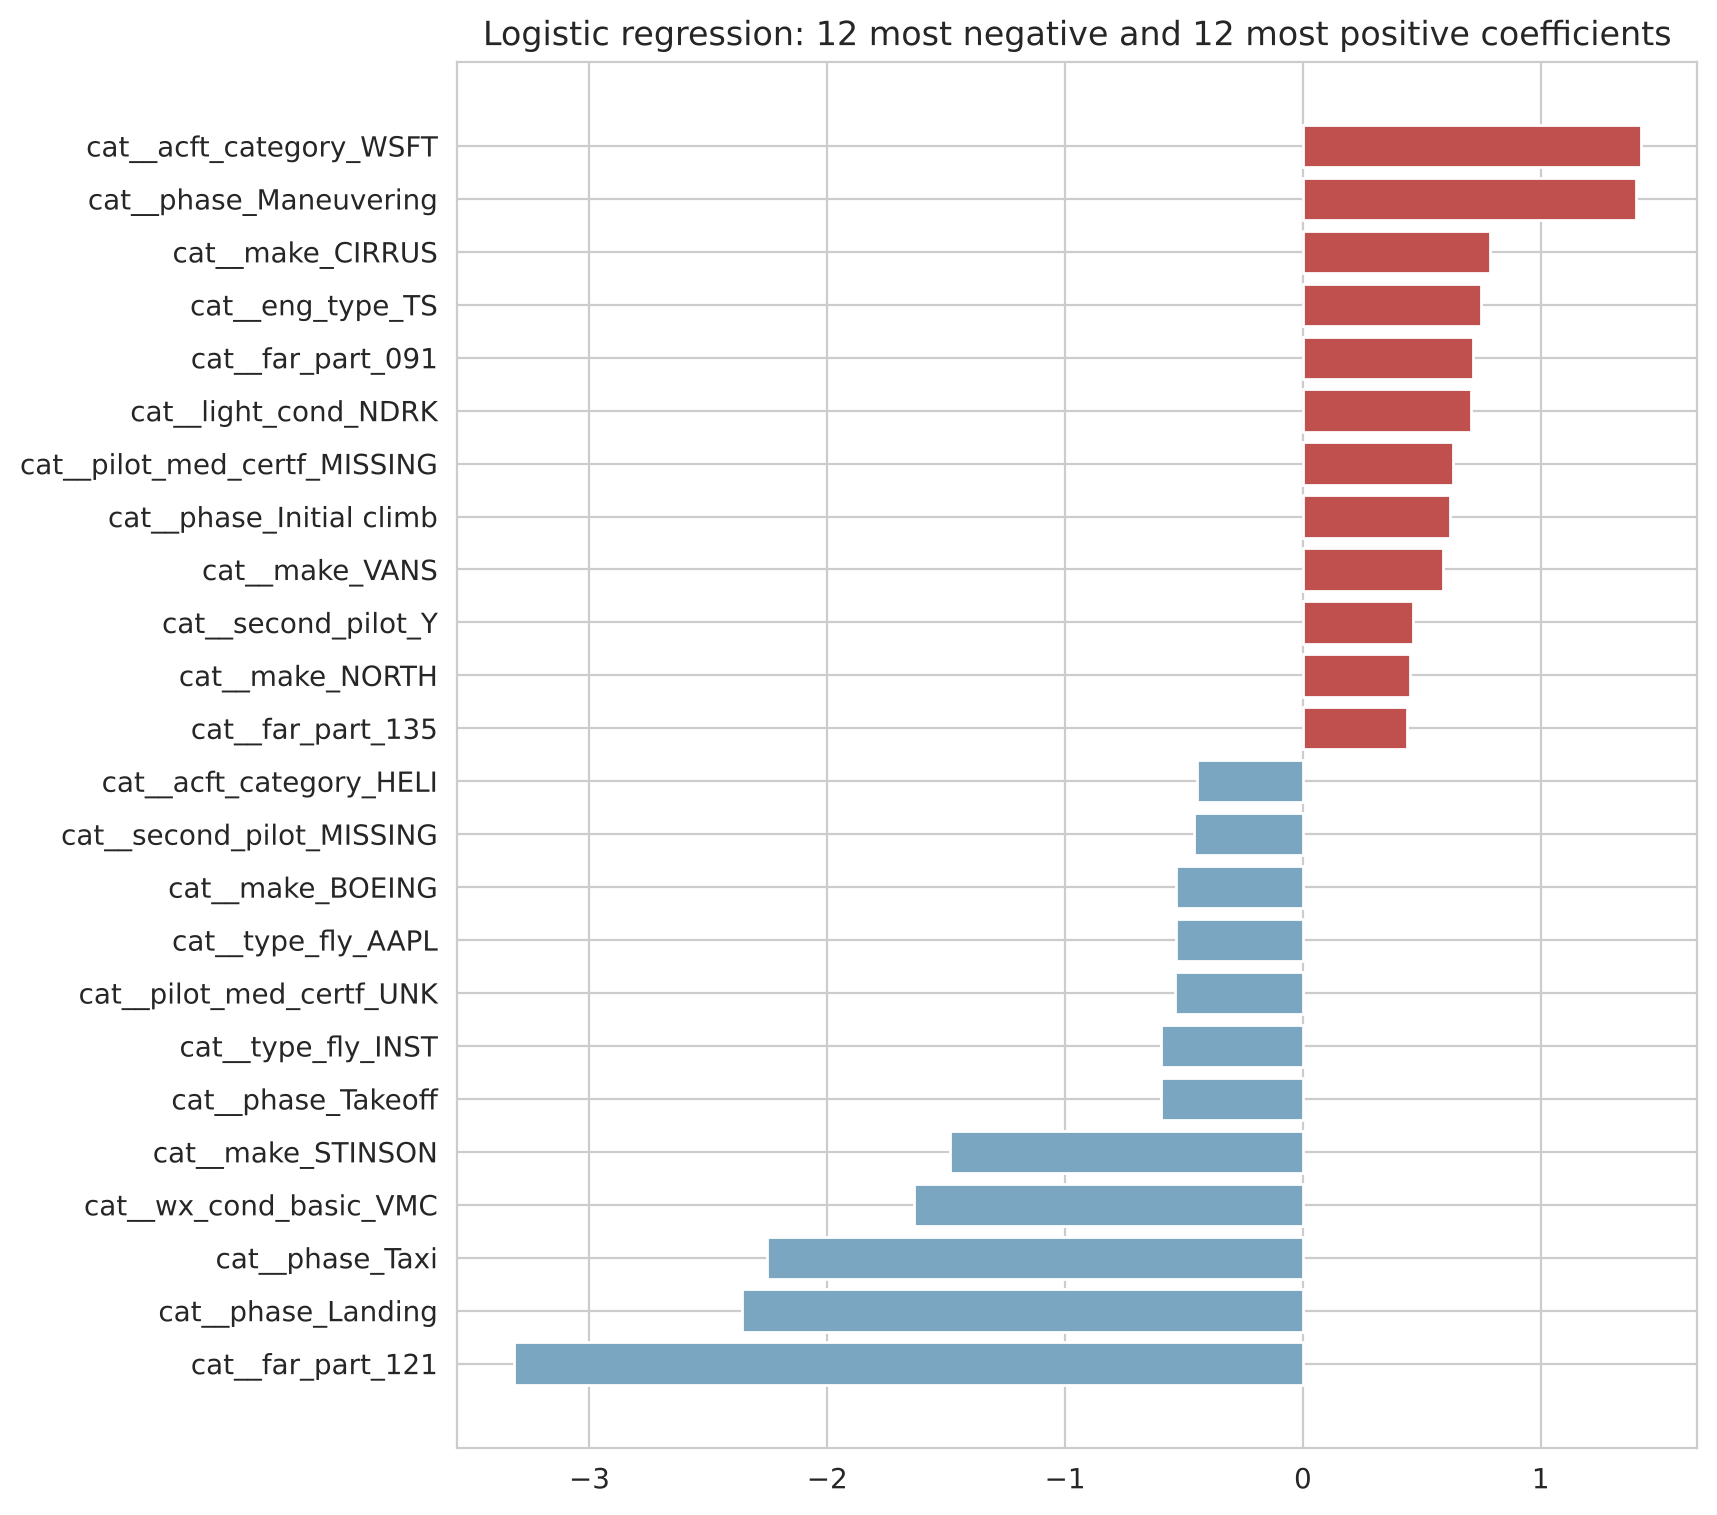

In [27]:
# logistic regression coefficients (on standardised / one-hot columns): positive = more likely fatal
lr_model = searches["Logistic regression"].best_estimator_.fit(X_train_fe, y_train)
names = lr_model.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr_model.named_steps["model"].coef_[0], index=names)
top = pd.concat([coef.sort_values().head(12), coef.sort_values().tail(12)])

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(top.index, top.values, color=["#7aa6c2" if v < 0 else "#c0504d" for v in top.values])
ax.set_title("Logistic regression: 12 most negative and 12 most positive coefficients")
plt.show()

**Which conditions make accidents more severe?**

- **Phase of flight dominates everything.** Shuffling it costs the forest 0.20 of AUC, 20 times more than any other feature. In the logistic regression, *Maneuvering* and *Initial climb* push towards fatal, *Landing*, *Taxi* and *Takeoff* push strongly away: accidents at low speed on or near the runway are rarely fatal; losses of control in flight are.
- **Weather and light**: VMC (good visibility) has one of the strongest negative coefficients, and dark night (`NDRK`) a positive one. Flying into clouds or darkness without visual references remains one of the deadliest situations.
- **Type of operation**: airline flights (`far_part` 121) have the strongest negative coefficient of all: airliners are built to protect occupants and flown by two professional crews. General aviation (091) and air taxi (135) go the other way. Instructional flights (`INST`) and aerial application (`AAPL`) are safer than average.
- **Aircraft**: weight-shift aircraft (`WSFT`), retractable landing gear (faster aircraft, `fixed_retractable` is the 2nd most important feature for the forest) and some manufacturers of fast, high-performance aircraft (e.g. Cirrus, Van's homebuilts) are associated with fatality; helicopters are less likely fatal than aeroplanes once the other conditions are taken into account.
- **Distance from the airport** (`log_apt_dist`) is among the top features: an accident far from a runway usually means an uncontrolled impact.

*Caveat:* permutation importance spreads the credit between correlated features. `light_cond` and `night`, or `imc` and `wx_cond_basic`, look unimportant individually because shuffling one leaves the other; together they matter. These are **associations**, not causes: the model tells the Guild where to look, not why it happened.

## 12. Final model for NB9

In [28]:
print("features (numerical):  ", num_sel)
print("features (categorical):", cat_sel)
print("model:", final_model.named_steps["model"])
print("threshold:", final_threshold)

features (numerical):   ['ev_hour', 'vis_sm', 'wx_temp', 'wx_dew_pt', 'altimeter', 'apt_elev', 'num_eng', 'total_seats', 'pilot_age', 'eng_power_hp', 'acft_age', 'temp_dew_spread', 'night', 'imc', 'log_apt_dist', 'has_ceiling']
features (categorical): ['light_cond', 'wx_cond_basic', 'sky_cond_ceil', 'sky_cond_nonceil', 'far_part', 'acft_category', 'homebuilt', 'fixed_retractable', 'type_fly', 'flt_plan_filed', 'second_pilot', 'eng_type', 'carb_fuel_injection', 'pilot_med_certf', 'phase', 'make']
model: RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=5,
                       n_estimators=300, n_jobs=-1, random_state=5)
threshold: 0.5


**Final model (used in NB9)**

| Step | Choice |
|---|---|
| Cleaning | `clean()` (section 3) |
| Feature engineering | `engineer()` (section 4) |
| Features | the 16 numerical + 16 categorical features printed above |
| Preprocessing | median imputation + missing indicators + standard scaling; `MISSING` category + one-hot with `min_frequency=30` |
| Model | `RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=5, max_features="sqrt", class_weight="balanced_subsample", random_state=5)` |
| Threshold | 0.50 |
| Expected F1 | ≈ 0.53-0.54 (CV 0.541, test 0.531) |

In NB9 the model is trained on **all of `learn.csv`** (train + test): now that every decision is made, using 20% more data can only help the final predictions.